# Image Super-Resolution

A neural field can upsample an image: fitted to the low-resolution (LR) pixels
through the degradation that made them, it renders the image at high resolution
(HR). This notebook recovers image 0887 of the DIV2K validation set from its 4×
bicubic downsampling under the super-resolution benchmark's protocol: about 500k
parameters each, and 1000 steps of Adam, each on 135 random blocks of 8 × 8 LR
pixels, with a cosine-annealed learning rate. It compares FUTON, with a sinc and
a cosine basis, against four representative baselines of the benchmark: SIREN
and FINER (periodic activations), Instant-NGP (a hash grid) and TensoRF (a grid
factorization), with bicubic interpolation as the reference. No model sees the
HR image, which only scores the results. Every setting is that of
`configs/super_resolution.yaml`, which holds every model of the benchmark.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib.ticker import (
    FixedLocator,
    MaxNLocator,
    MultipleLocator,
    NullFormatter,
    StrMethodFormatter,
)
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image
from torchvision.transforms.functional import pil_to_tensor

import inro

set_matplotlib_formats("retina")  # sharp figures on high-resolution screens
sns.set_theme(
    context="notebook", style="whitegrid", font_scale=0.85, rc={"grid.color": ".92"}
)

colorblind = sns.color_palette("colorblind")
# FUTON in black, its cosine basis dashed; the periodic activations in warm
# hues and the grids in cool ones.
PALETTE = {
    "FUTON (sinc)": "black",
    "FUTON (cosine)": "black",
    "RFF": colorblind[4],
    "SIREN": colorblind[1],
    "FINER": colorblind[3],
    "Instant-NGP": colorblind[2],
    "TensoRF": colorblind[0],
}
DASHES = {model: (4, 2) if model == "FUTON (cosine)" else "" for model in PALETTE}
# seaborn's own markers, each fixed to a model as its colour is
MARKERS = dict(zip(PALETTE, ["o", "X", (4, 0, 45), "P", (4, 0, 0), (4, 1, 0), "^"]))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


The plotting helpers: training time on a log axis, the metric on whole
decibels or half points, a summary table, images side by side, and
reconstructions above their errors.

In [2]:
NICE = [1, 2, 5, 10]  # tick steps: 1, 2 or 5 times a power of ten


def time_axis(ax, times):
    """Training time on a log axis, ticked 1, 2, 5, 10, ... in plain numbers."""
    low, high = times.min() / 1.1, times.max() * 1.1
    ax.set(xscale="log", xlim=(low, high), xlabel="Training time (s)")
    for subs in ((1, 2, 5), (1,)):
        ticks = [m * 10.0**k for k in range(-3, 6) for m in subs]
        ticks = [tick for tick in ticks if low <= tick <= high]
        if len(ticks) <= 7:
            break
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())


def metric_axis(ax, metric, low, high):
    """The metric's axis over [low, high]: whole decibels for a PSNR, half
    points for an IoU, which cannot pass 100."""
    if metric == "IoU (%)":
        low = np.floor(2 * low) / 2
        ax.set_ylim(low, min(max(np.ceil(2 * high) / 2, low + 0.5), 100))
        ax.yaxis.set_major_locator(MultipleLocator(0.5))
    else:
        low = np.floor(low)
        ax.set_ylim(low, max(np.ceil(high), low + 1))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=NICE, integer=True))


def table(summary, formats, better):
    """The summary, each column in its format and, in each column of
    ``better`` ("higher" or "lower"), the best value bold and the second
    underlined."""

    def marks(column):
        rank = column.rank(method="min", ascending=better[column.name] == "lower")
        looks = {1: "font-weight: bold", 2: "text-decoration: underline"}
        return [looks.get(r, "") for r in rank]

    return (
        summary.style.format(formats, na_rep="")
        .apply(marks, subset=list(better))
        .hide(axis="index")
    )


def show(panels, ncols, width=11, **imshow):
    """Images side by side under their titles, in rows of ``ncols``, each
    drawn at the size of the first."""
    height, side = panels[0][1].shape[:2]
    nrows = -(-len(panels) // ncols)
    room = 0.45 if any("\n" in title for title, _ in panels) else 0.3
    fig, axes = plt.subplots(
        nrows,
        ncols,
        squeeze=False,
        layout="constrained",
        figsize=(width, nrows * (width / ncols * height / side + room)),
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, image) in zip(axes.flat, panels):
        ax.imshow(image, interpolation="nearest", **imshow)
        ax.set_title(title, fontsize=9)
    return fig


def compare(panels, label, width=11):
    """The reference and the reconstructions in a row under their titles
    (``panels``, the reference first), and beneath each reconstruction its
    absolute error, averaged over the colour channels; the errors share one
    scale, which saturates at their 99th percentile, and its colour bar
    stands beneath the reference."""
    reference = panels[0][1].astype(float)
    errors = [np.abs(image - reference).mean(-1) for _, image in panels[1:]]
    height, side = reference.shape[:2]
    ncols = len(panels)
    fig, axes = plt.subplots(
        2,
        ncols,
        layout="constrained",
        figsize=(width, 2 * width / ncols * height / side + 0.45),
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, image) in zip(axes[0], panels):
        ax.imshow(image, interpolation="nearest")
        ax.set_title(title, fontsize=9)
    vmax = np.percentile(np.concatenate([error.ravel() for error in errors]), 99)
    for ax, error in zip(axes[1, 1:], errors):
        maps = ax.imshow(
            error, cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
    bar = fig.colorbar(maps, cax=axes[1, 0].inset_axes([0.8, 0.04, 0.07, 0.92]))
    bar.ax.yaxis.set_ticks_position("left")
    bar.ax.yaxis.set_label_position("left")
    bar.ax.yaxis.set_major_locator(MaxNLocator(nbins=4, steps=NICE))
    bar.ax.tick_params(labelsize=8)
    bar.set_label(label, fontsize=9)
    bar.outline.set_visible(False)
    return fig

## Data

The HR image and the LR image that the fields see, with the region that the
comparison at the end magnifies: the castle's windows, whose arches and
mullions span a few LR pixels.

HR: 1356 x 2040 pixels, LR: 339 x 510


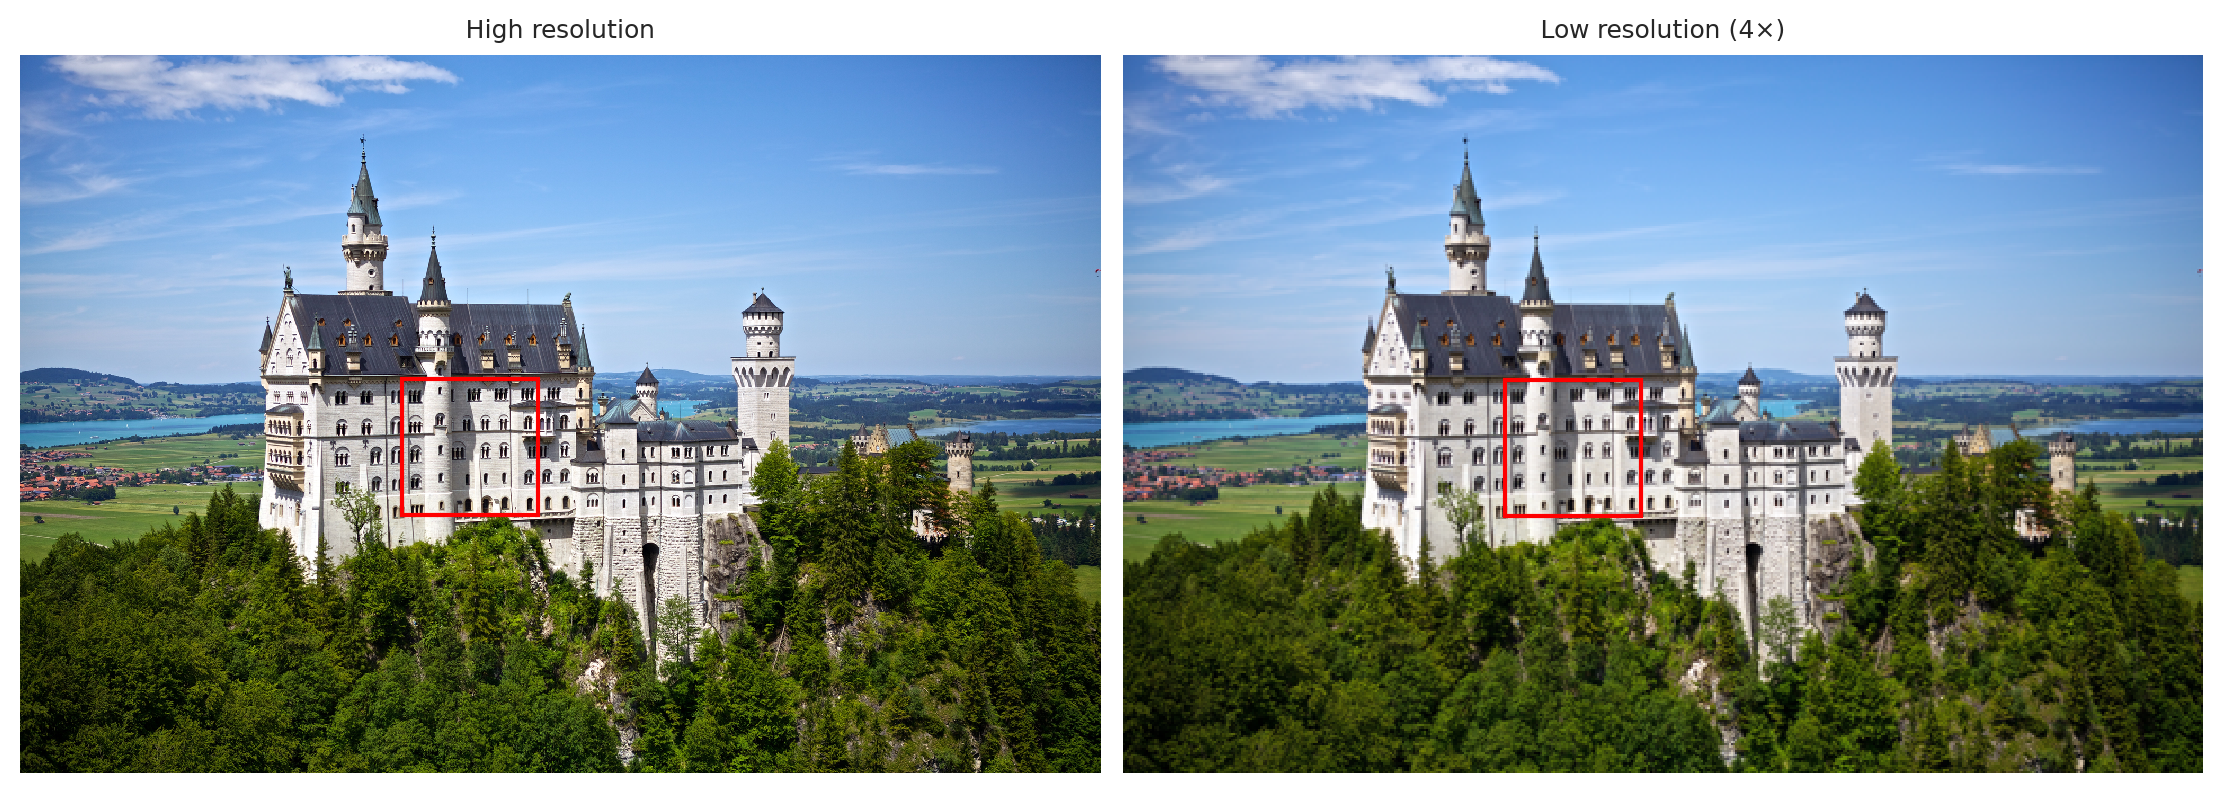

In [3]:
SCALE = 4
HR_PATH = "../data/DIV2K/DIV2K_valid_HR/0887.png"
LR_PATH = f"../data/DIV2K/DIV2K_valid_LR_bicubic/X{SCALE}/0887x{SCALE}.png"
CROP = (slice(612, 868), slice(721, 977))  # rows and columns: the castle's windows

image = inro.ImageCoordinateDataset(HR_PATH)  # every HR pixel, for evaluation
image_lr = Image.open(LR_PATH).convert("RGB")
(H, W), (h, w) = image.grid_size, (image_lr.height, image_lr.width)
original = image.original.permute(1, 2, 0).numpy()  # (H, W, 3), uint8
print(f"HR: {H} x {W} pixels, LR: {h} x {w}")

fig = show(
    [
        ("High resolution", original),
        (f"Low resolution ({SCALE}×)", np.asarray(image_lr)),
    ],
    ncols=2,
)
for ax, scale in zip(fig.axes, (1, SCALE)):  # the region on either image
    rows, columns = (slice(s.start // scale, s.stop // scale) for s in CROP)
    box = plt.Rectangle(
        (columns.start, rows.start),
        columns.stop - columns.start,
        rows.stop - rows.start,
    )
    ax.add_patch(box).set(fill=False, edgecolor="red", linewidth=1.5)
plt.show()

## Bicubic Interpolation

Every result is scored against the HR image as is standard, by
`inro.super_resolution_metrics`: PSNR and SSIM on luma, and LPIPS on RGB, all
without a 4-pixel border. Bicubic interpolation, the standard reference, needs
no training; PIL's bicubic filter is that of MATLAB's `imresize`. The plots
show its PSNR as a dotted level.

In [4]:
# Each called as metric(reconstruction, original) on uint8 (3, H, W) images.
METRICS = inro.super_resolution_metrics(border=SCALE, device=device)

upsampled = image_lr.resize((W, H), Image.Resampling.BICUBIC)
bicubic = {
    name: metric(pil_to_tensor(upsampled), image.original)
    for name, metric in METRICS.items()
}
print(f"Bicubic: {bicubic['psnr']:.2f} dB")


def bicubic_level(ax, labelled=False):
    """Bicubic interpolation's PSNR as a dotted level, labelled at the right."""
    ax.axhline(bicubic["psnr"], color=".3", linestyle=":", linewidth=1.2)
    if labelled:
        ax.annotate(
            "Bicubic",
            (1, bicubic["psnr"]),
            xycoords=("axes fraction", "data"),
            xytext=(-3, 3),
            textcoords="offset points",
            ha="right",
            va="bottom",
            fontsize=8,
            color=".3",
        )

Bicubic: 24.81 dB


## Forward Model

The benchmark's degradation, antialiased bicubic downsampling as MATLAB's
`imresize` computes it, is linear and separable: one matrix per axis describes
it exactly, borders included. `inro.resize_matrix` writes that matrix out by
resizing an identity image along the axis, and `inro.downsample` applies one per
axis. Each of its rows holds at most `4 * SCALE` nonzero taps, the footprint
of one LR pixel along the axis. Applied to the HR image, the forward model
gives back the benchmark's LR image, up to rounding.

In [5]:
# (h, H) and (w, W): each LR row and column a weighted sum of HR ones
kernels = [inro.resize_matrix(H, h, device), inro.resize_matrix(W, w, device)]
print(f"Taps per LR pixel and axis: {int((kernels[0] != 0).sum(1).max())}")

simulated = inro.downsample(image.original.movedim(0, -1).float().to(device), kernels)
simulated = simulated.round().clamp(0, 255).movedim(-1, 0).cpu()
fidelity = inro.psnr(simulated, pil_to_tensor(image_lr), data_range=255)
print(f"Forward model against the LR image: {fidelity:.2f} dB")

Taps per LR pixel and axis: 16
Forward model against the LR image: 57.40 dB


## Minibatches

Each step fits a fixed number of random blocks of LR pixels, whatever the
image's size, and the field renders only the HR pixels under their kernels:
`inro.SuperResolutionDataset` draws the blocks, with the HR coordinates of their
footprints and the kernel rows on those. Neighbouring LR pixels share most of
their footprint, so a block needs far fewer field evaluations per pixel than
single pixels do: 30 in an 8 × 8 block against 256 alone. The loss,
`inro.super_resolution_loss`, downsamples each rendered footprint along both
axes and takes the mean absolute error against the LR pixels, the usual loss
in super-resolution.

In [6]:
train_dataset = inro.SuperResolutionDataset(
    LR_PATH, kernels, num_blocks=135, block_size=8
)

## Models

Each entry gives a model's class, its arguments and its learning rate.
`# deviation` marks a setting that departs from the authors' code, with the
reason. Every learning rate, and every setting marked `# tuned`, maximizes the
mean PSNR over three DIV2K training images (0395, 0431 and 0777) under this
protocol.

Every model has about 500k parameters, close to the 519k values of the LR
image, so that each can fit what it observes and the comparison rests on what
it adds between the pixels. A baseline takes the smallest size of its kind that
reaches the budget, and FUTON the largest CP rank, a multiple of 5, that keeps
it smaller than every baseline. FUTON has one basis function per LR pixel along
each axis, the bandwidth that the LR image determines.

In [7]:
# FUTON's rank: the largest multiple of 5 that keeps it smaller than every
# baseline (500,007 parameters for the smallest), where rank R costs R * (h + w)
# factor entries and R * 128 + 128 in the hidden layer of the decoder, whose
# output layer adds 3 * 128 + 3.
RANK = (500_006 - 4 * 128 - 3) // (h + w + 128) // 5 * 5

CONFIGS = [
    {
        "name": "SIREN",  # FINER image benchmark
        "class": inro.SIREN,
        "kwargs": {
            "hidden_features": 407,
            "hidden_layers": 4,
            "omega": 120.0,  # tuned
            "output_activation": torch.tanh,
        },
        "lr": 1e-4,
    },
    {
        "name": "FINER",  # FINER image benchmark
        "class": inro.FINER,
        "kwargs": {
            "hidden_features": 407,
            "hidden_layers": 4,
            "omega": 120.0,  # tuned
            "output_activation": torch.tanh,
        },
        "lr": 1e-4,
    },
    {
        "name": "Instant-NGP",  # instant-ngp configs/image/base.json
        "class": inro.InstantNGP,
        "kwargs": {
            "num_levels": 17,  # deviation: 16 in the reference; 17 meets the budget
            "features_per_level": 2,
            "log2_hashmap_size": 15,
            "base_resolution": 16,
            "max_resolution": max(h, w),  # tuned: the LR grid
            "hidden_features": 64,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,  # deviation: 1e-2 in the reference
    },
    {
        "name": "TensoRF",
        "class": inro.TensoRF,
        "kwargs": {
            "rank": 566,
            "resolution": max(h, w) // 2,  # tuned: half the LR grid
            "mode": "cp",
            "hidden_features": 256,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,
    },
    {
        "name": "FUTON (sinc)",
        "class": inro.FUTON,
        "kwargs": {
            "basis": (  # on the HR pixels
                "sinc",
                {"num_components": (h, w), "grid_size": (H, W)},
            ),
            "combiner": ("cp", {"rank": RANK}),
            "decoder": ("mlp", {"hidden_layers": 1, "hidden_features": 128}),
            "output_activation": torch.tanh,
        },
        "lr": 1e-2,
    },
    {
        "name": "FUTON (cosine)",
        "class": inro.FUTON,
        "kwargs": {
            "basis": (  # on the HR pixels
                "cosine",
                {"num_components": (h, w), "grid_size": (H, W)},
            ),
            "combiner": ("cp", {"rank": RANK}),
            "decoder": ("mlp", {"hidden_layers": 1, "hidden_features": 128}),
            "output_activation": torch.tanh,
        },
        "lr": 1e-2,
    },
]

## Training

Each step fits 135 blocks of 8 × 8 LR pixels, whose footprints hold 261,360 HR
pixels, about 2^18. Every 50 steps the field renders the whole HR image, which
is scored.

Every model is compiled with `torch.compile`, and an untimed forward and
backward pass compiles it before training starts. The training times exclude
that compilation and the evaluations.

In [8]:
CHUNK = 2**18  # HR pixels per forward pass when evaluating
results = {}

for config in CONFIGS:
    torch.manual_seed(0)
    model = config["class"](in_features=2, out_features=3, **config["kwargs"])
    print(f"{config['name']}: {inro.count_parameters(model):,} parameters")
    model.to(device).compile()
    model(train_dataset[0]["input"][None].to(device)).sum().backward()  # compiles it
    model.zero_grad(set_to_none=True)
    result = inro.train(
        model,
        train_dataset,
        image,
        loss_fn=inro.super_resolution_loss,
        lr=config["lr"],
        num_steps=1000,
        metrics=METRICS,
        log_interval=50,
        eval_interval=50,
        chunk_size=CHUNK,
        device=device,
        **config.get("train_kwargs", {}),
    )
    output = inro.chunked_inference(model, image.input, chunk_size=CHUNK, device=device)
    result["reconstruction"] = image.postprocess(output.cpu()).permute(1, 2, 0).numpy()
    results[config["name"]] = result

    del model, output, result["model_dict"]
    torch.cuda.empty_cache()
    torch.compiler.reset()  # the next model compiles anew

SIREN: 500,613 parameters
FINER: 500,613 parameters
Instant-NGP: 505,168 parameters
TensoRF: 500,375 parameters
FUTON (sinc): 498,785 parameters
FUTON (cosine): 498,785 parameters


## Convergence

The PSNR of the HR image, every 50 steps; the dotted level is bicubic
interpolation's.

FUTON is black, its cosine basis dashed; the periodic activations have warm
hues and the grids cool ones.

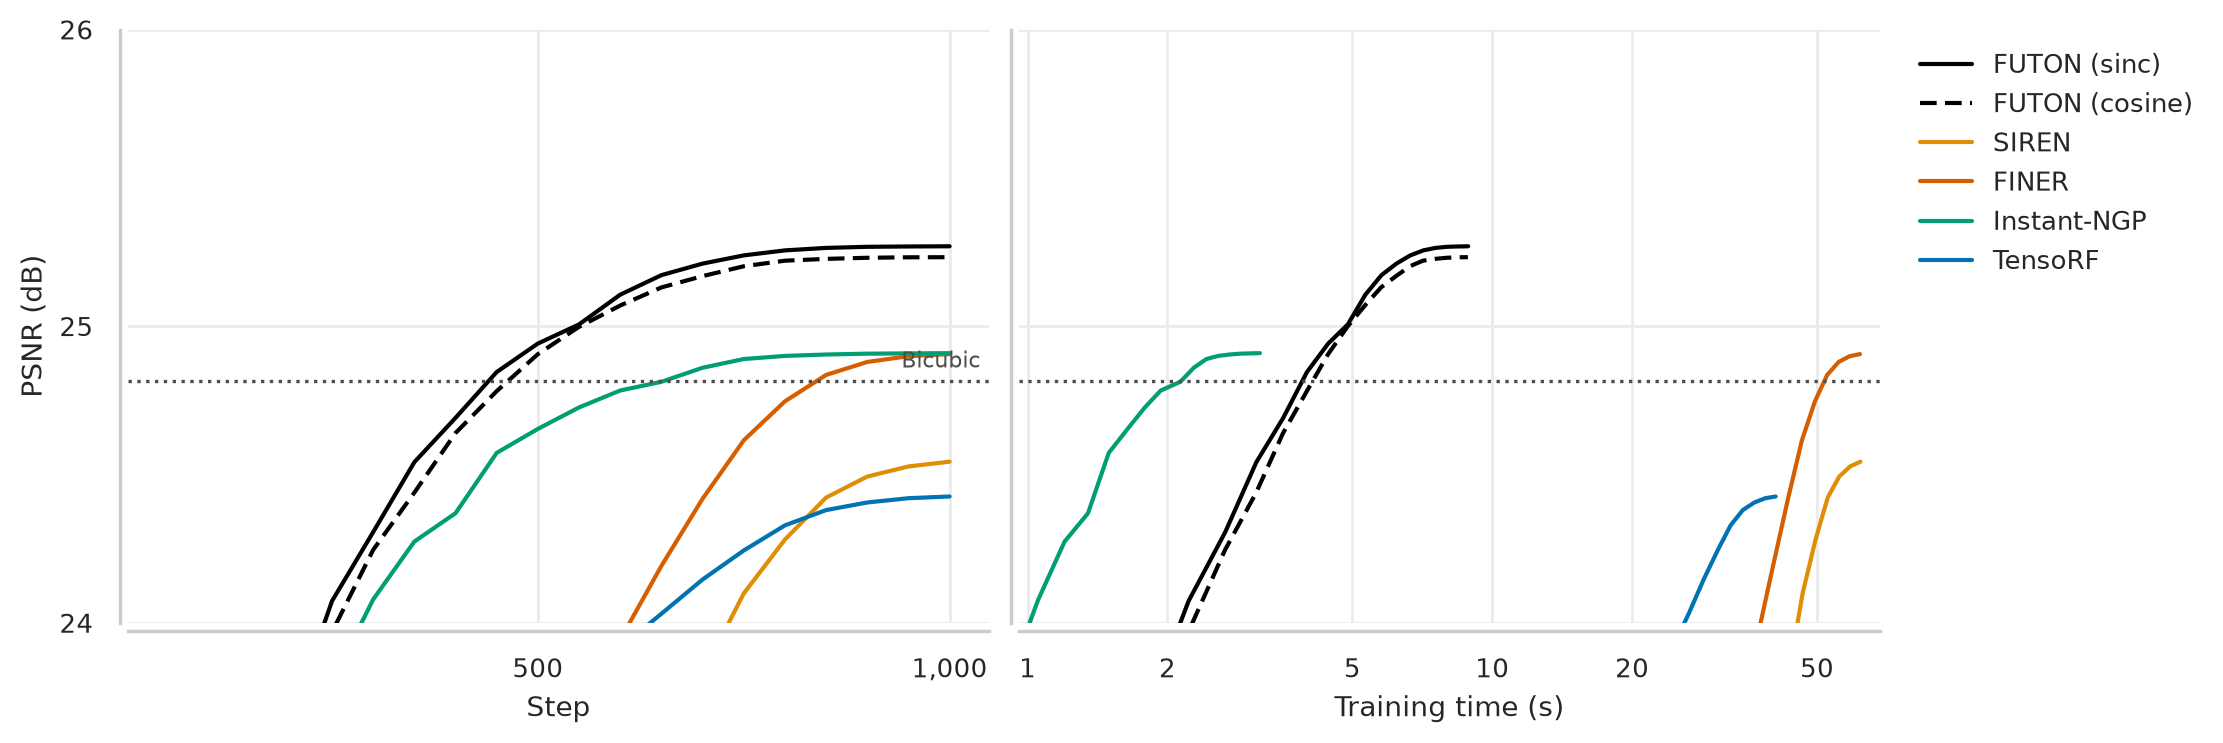

In [9]:
records = pd.DataFrame(
    {
        "Model": name,
        "Step": entry["step"],
        "Time (s)": entry["elapsed"],
        "PSNR (dB)": entry["eval"]["psnr"],
    }
    for name, result in results.items()
    for entry in result["history"]
    if "eval" in entry
)

order = [model for model in PALETTE if model in set(records["Model"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, x in zip(axes, ("Step", "Time (s)")):
    sns.lineplot(
        records,
        x=x,
        y="PSNR (dB)",
        hue="Model",
        style="Model",
        hue_order=order,
        style_order=order,
        palette=PALETTE,
        dashes=DASHES,
        legend=ax is axes[1],
        ax=ax,
    )
    bicubic_level(ax, labelled=ax is axes[0])
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5, steps=NICE))
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
final = records.groupby("Model")["PSNR (dB)"].last()
low = min(final.min(), bicubic["psnr"])
high = max(records["PSNR (dB)"].max(), bicubic["psnr"])
margin = 0.05 * (high - low)  # so that no curve ends on the frame
metric_axis(axes[0], "PSNR (dB)", low - margin, high + margin)
shown = records["PSNR (dB)"] >= axes[0].get_ylim()[0]  # the evaluations in view
time_axis(axes[1], records.loc[shown, "Time (s)"])

sns.move_legend(
    axes[-1], "upper left", bbox_to_anchor=(1.02, 1), title=None, frameon=False
)
sns.despine(fig, offset=3)
plt.show()

## Summary

Throughput is the median rate of the evaluations, which reconstruct the whole
HR image, and inference memory their median peak; training memory is the peak
of training. Bicubic interpolation trains nothing and runs on the CPU, so it
has scores but no costs. In each column the best value is bold and the second
underlined.

In [10]:
rows = []
for name, result in results.items():
    evaluations = [entry["eval"] for entry in result["history"] if "eval" in entry]
    duration = np.median([e["duration"] for e in evaluations])
    memory = np.median([e["peak_memory"] for e in evaluations])
    rows.append(
        {
            "Model": name,
            "Params (k)": result["config"]["num_params"] / 1e3,
            "Training time (s)": result["history"][-1]["elapsed"],
            "Training memory (MB)": result["config"]["peak_memory"] / 1e6,
            "Throughput (MPix/s)": H * W / duration / 1e6,
            "Inference memory (MB)": memory / 1e6,
            "PSNR (dB)": evaluations[-1]["psnr"],
            "SSIM": evaluations[-1]["ssim"],
            "LPIPS": evaluations[-1]["lpips"],
        }
    )
rows.append(
    {
        "Model": "Bicubic",
        "PSNR (dB)": bicubic["psnr"],
        "SSIM": bicubic["ssim"],
        "LPIPS": bicubic["lpips"],
    }
)
summary = pd.DataFrame(rows).sort_values("PSNR (dB)", ascending=False)

formats = {
    "Params (k)": "{:.1f}",
    "Training time (s)": "{:.1f}",
    "Training memory (MB)": "{:.0f}",
    "Throughput (MPix/s)": "{:.1f}",
    "Inference memory (MB)": "{:.0f}",
    "PSNR (dB)": "{:.2f}",
    "SSIM": "{:.3f}",
    "LPIPS": "{:.3f}",
}
better = {
    "Training time (s)": "lower",
    "Training memory (MB)": "lower",
    "Throughput (MPix/s)": "higher",
    "Inference memory (MB)": "lower",
    "PSNR (dB)": "higher",
    "SSIM": "higher",
    "LPIPS": "lower",
}
table(summary, formats, better)

Model,Params (k),Training time (s),Training memory (MB),Throughput (MPix/s),Inference memory (MB),PSNR (dB),SSIM,LPIPS
FUTON (sinc),498.8,8.9,827,76.9,698,25.27,0.721,0.383
FUTON (cosine),498.8,8.9,826,76.0,699,25.23,0.720,0.399
Instant-NGP,505.2,3.2,429,155.6,315,24.91,0.706,0.384
FINER,500.6,61.8,3835,14.5,884,24.91,0.695,0.426
Bicubic,,,,,,24.81,0.702,0.372
SIREN,500.6,62.0,3833,14.5,882,24.54,0.687,0.416
TensoRF,500.4,40.7,2375,28.4,890,24.43,0.686,0.416


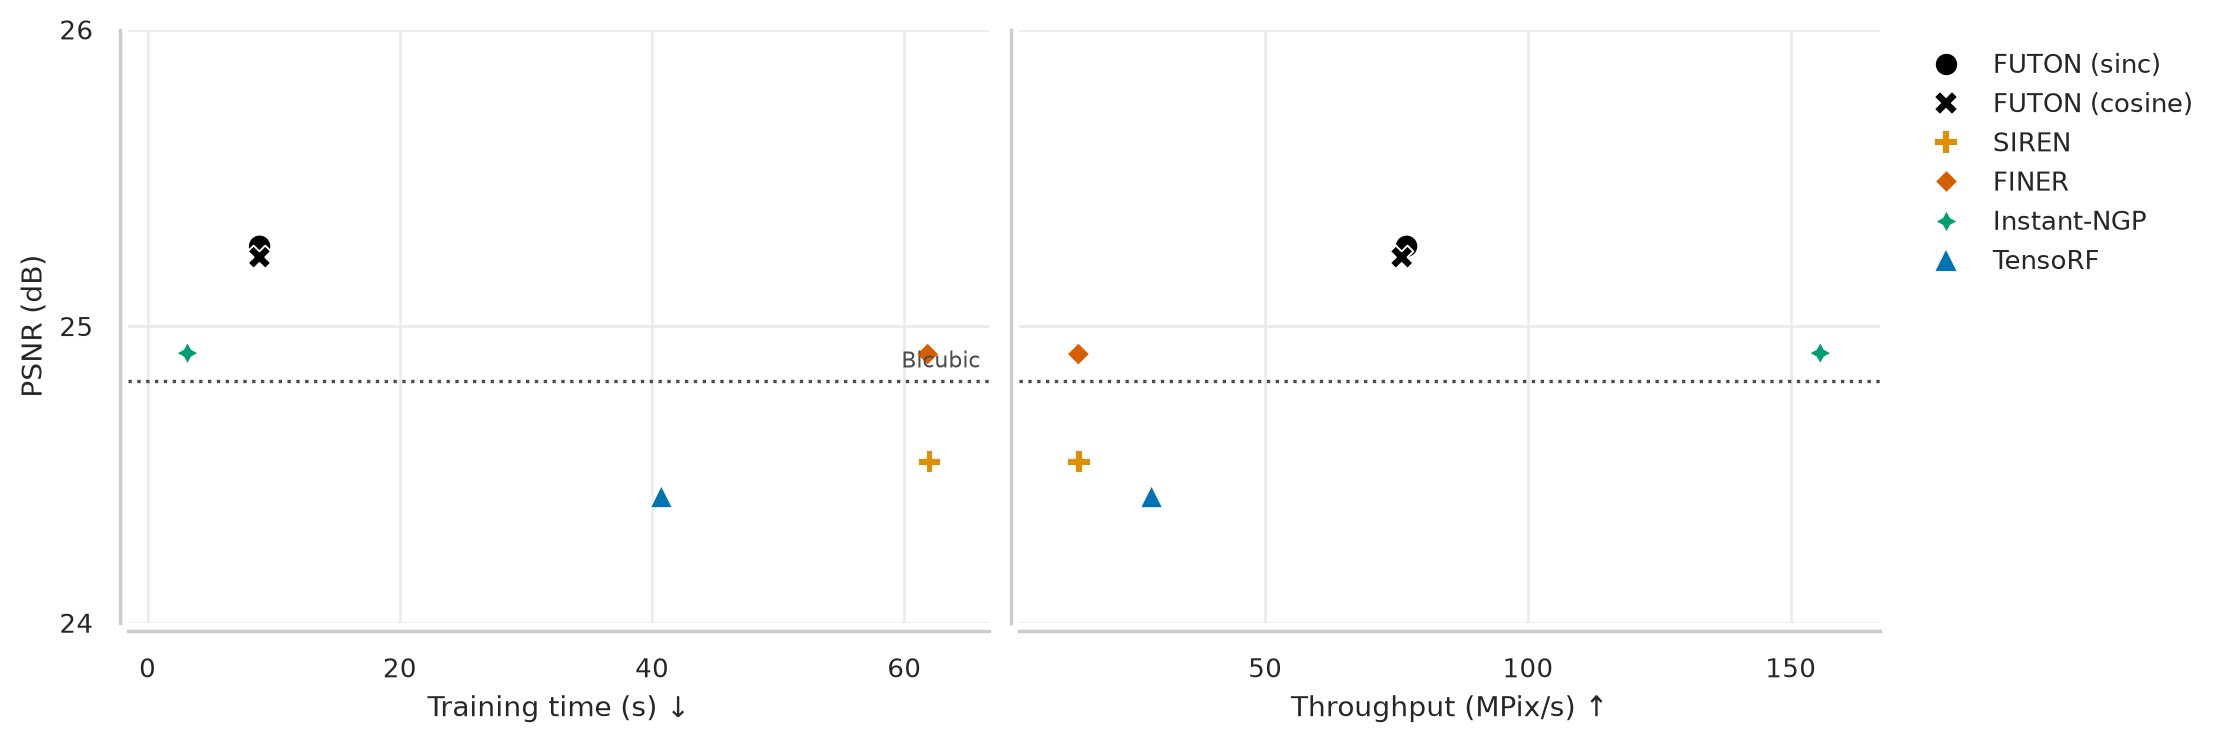

In [11]:
fields = summary[summary["Model"].isin(results)]  # the trained models

order = [model for model in PALETTE if model in set(fields["Model"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, cost in zip(axes, ("Training time (s)", "Throughput (MPix/s)")):
    sns.scatterplot(
        fields,
        x=cost,
        y="PSNR (dB)",
        hue="Model",
        style="Model",
        hue_order=order,
        style_order=order,
        palette=PALETTE,
        markers=MARKERS,
        s=70,
        legend=ax is axes[1],
        ax=ax,
    )
    bicubic_level(ax, labelled=ax is axes[0])
    ax.margins(x=0.08)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=NICE))
axes[0].set_xlabel("Training time (s) ↓")
axes[1].set_xlabel("Throughput (MPix/s) ↑")
low = min(fields["PSNR (dB)"].min(), bicubic["psnr"])
high = max(fields["PSNR (dB)"].max(), bicubic["psnr"])
metric_axis(axes[0], "PSNR (dB)", low - 0.08 * (high - low), high + 0.08 * (high - low))

sns.move_legend(
    axes[-1], "upper left", bbox_to_anchor=(1.02, 1), title=None, frameon=False
)
sns.despine(fig, offset=3)
plt.show()

## Qualitative Comparison

The castle's windows in every reconstruction, titled with its PSNR on the whole
image, and beneath, the error of each, averaged over the colour channels, on
one scale. Their arches and mullions span a few LR pixels, so what a model draws
between those pixels comes from its inductive bias.

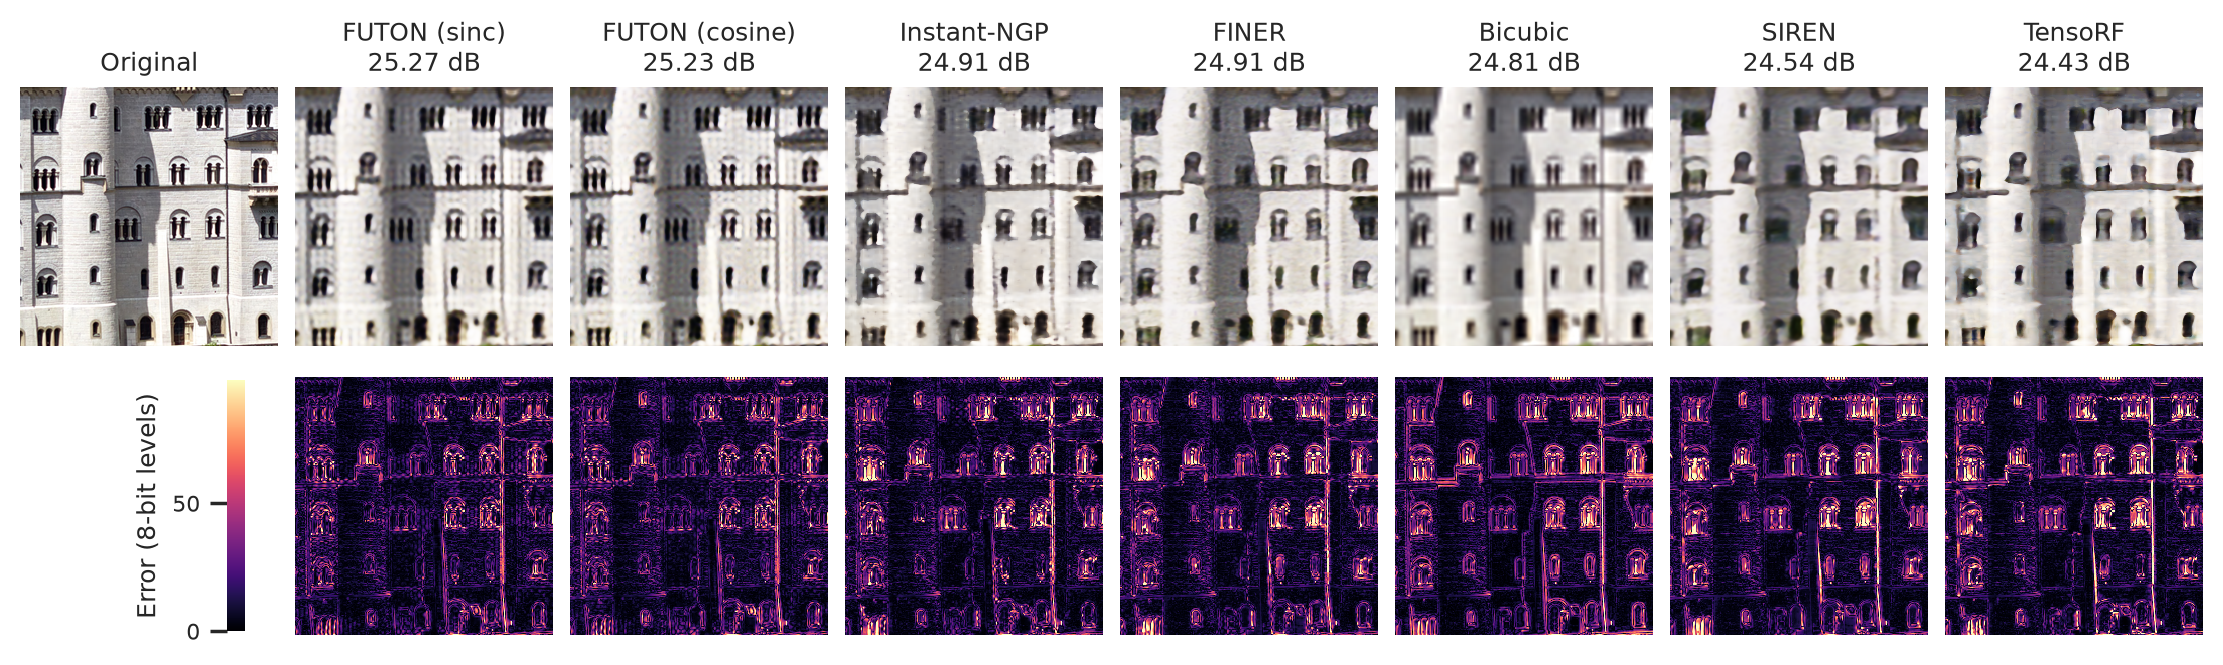

In [12]:
reconstructions = {name: result["reconstruction"] for name, result in results.items()}
reconstructions["Bicubic"] = np.asarray(upsampled)
crops = [("Original", original[CROP])] + [
    (f"{name}\n{psnr:.2f} dB", reconstructions[name][CROP])
    for name, psnr in zip(summary["Model"], summary["PSNR (dB)"])
]
compare(crops, "Error (8-bit levels)")
plt.show()